# Activité Pratique N°3 — RAG Multi Modal Agentique
## Étape 1 — Extraction du contenu multimodal (textes et images)

**IA Générative Multi Modale — 5IAD G1, EMSI** · Étudiant : BENHAYOUN SADAFI Mohamed

**Objectif de cette étape :** extraire le texte intégral du PDF page par page, le découper en fragments (chunks), et extraire les images.

Document source : *Attention Is All You Need* (`pdfs/attention is all you need.pdf`).

```
attention is all you need.pdf ──► PyMuPDF ──► resultats_pdf/
                                               ├── images/  page_003_image_94.png, page_004_image_102.png, …
                                               ├── textes/  page_001.txt … page_011.txt
                                               └── texte_complet.txt
```

In [1]:
import base64
import hashlib
import json
import os
import re
from io import BytesIO
from pathlib import Path

from IPython.display import Markdown, display
from PIL import Image

RACINE = Path.cwd()
PDF_PATH = RACINE / "pdfs" / "attention is all you need.pdf"
OUTPUT_DIR = RACINE / "resultats_pdf"
TEXT_DIR = OUTPUT_DIR / "textes"
IMAGE_DIR = OUTPUT_DIR / "images"
CHROMA_DIR = RACINE / "chroma_db"
COLLECTION_NOM = "pdf_clip_vit_b32"
IMAGE_REQUETE = RACINE / "images_requetes" / "architecture_transformer.png"
print("PDF :", PDF_PATH.name, "| existe :", PDF_PATH.is_file())

PDF : attention is all you need.pdf | existe : True


In [2]:
import pymupdf

TEXT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

textes, nombre_images, pages_sans_texte = [], 0, []
with pymupdf.open(PDF_PATH) as document:
    nombre_pages = len(document)
    for numero_page, page in enumerate(document, start=1):
        # Texte de la page (sort=True : ordre de lecture haut -> bas, gauche -> droite)
        texte = page.get_text("text", sort=True)
        (TEXT_DIR / f"page_{numero_page:03d}.txt").write_text(texte, encoding="utf-8")
        textes.append(f"===== PAGE {numero_page} =====\n\n{texte}")
        if not texte.strip():
            pages_sans_texte.append(numero_page)

        # Images intégrées (chaque xref n'est extrait qu'une fois par page)
        vues = set()
        for info in page.get_images(full=True):
            xref = info[0]
            if xref in vues:
                continue
            vues.add(xref)
            image = document.extract_image(xref)
            if image:
                fichier = IMAGE_DIR / f"page_{numero_page:03d}_image_{xref}.{image['ext']}"
                fichier.write_bytes(image["image"])
                nombre_images += 1

(OUTPUT_DIR / "texte_complet.txt").write_text("\n\n".join(textes), encoding="utf-8")
print(f"Pages traitées : {nombre_pages}")
print(f"Images enregistrées : {nombre_images}")
print("Pages sans texte :", pages_sans_texte or "aucune")

Pages traitées : 11
Images enregistrées : 3
Pages sans texte : aucune


### Aperçu du texte et des images extraits

In [3]:
texte_complet = (OUTPUT_DIR / "texte_complet.txt").read_text(encoding="utf-8")
print(f"{len(texte_complet):,} caractères au total\n")
print(texte_complet[:1200])

36,551 caractères au total

===== PAGE 1 =====

             Attention Is All You Need





     Ashish Vaswani∗      Noam Shazeer∗       Niki Parmar∗     Jakob Uszkoreit∗
      Google Brain          Google Brain       Google Research     Google Research
  avaswani@google.com   noam@google.com   nikip@google.com   usz@google.com

        Llion Jones∗          Aidan N. Gomez∗†            Łukasz Kaiser∗
     Google Research          University of Toronto              Google Brain
    llion@google.com     aidan@cs.toronto.edu     lukaszkaiser@google.com

                                               Illia Polosukhin∗‡
                         illia.polosukhin@gmail.com


                                Abstract

       The dominant sequence transduction models are based on complex recurrent or
        convolutional neural networks that include an encoder and a decoder. The best
        performing models also connect the encoder and decoder through an attention
       mechanism. We propos

page_003_image_94.png | (1520, 2239) RGB


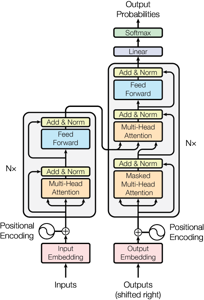

page_004_image_102.png | (835, 1282) RGB


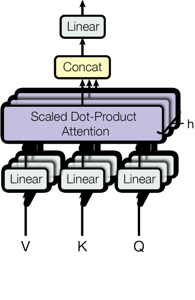

page_004_image_104.png | (445, 884) RGB


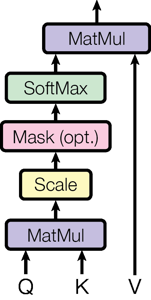

In [4]:
for fichier in sorted(IMAGE_DIR.iterdir()):
    with Image.open(fichier) as img:
        print(fichier.name, "|", img.size, img.mode)
        apercu = img.convert("RGB")
    apercu.thumbnail((300, 300))
    display(apercu)

### Découpage du texte en fragments (chunks)

Le modèle d'embedding CLIP accepte au plus **77 tokens** par texte. On découpe donc chaque page en fragments de **60 tokens BPE** (le tokenizer de CLIP) avec **10 tokens de chevauchement**, pour qu'une phrase coupée en deux reste retrouvable.

In [5]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from open_clip.tokenizer import SimpleTokenizer

bpe = SimpleTokenizer()   # tokenizer BPE de CLIP


def decouper_texte(texte, taille=60, chevauchement=10):
    # Fenêtres glissantes de `taille` tokens BPE, avec chevauchement.
    if not 0 <= chevauchement < taille:
        raise ValueError("Le chevauchement doit être inférieur à la taille.")
    tokens = bpe.encode(texte)
    for debut in range(0, len(tokens), taille - chevauchement):
        fragment = bpe.decode(tokens[debut:debut + taille]).strip()
        if fragment:
            yield fragment
        if debut + taille >= len(tokens):
            break


def decouper_texte_v2(texte, taille=60, chevauchement=10):
    # Variante : coupe de préférence aux limites naturelles (paragraphes, lignes, espaces).
    splitter = RecursiveCharacterTextSplitter(chunk_size=taille, chunk_overlap=chevauchement,
                                              length_function=lambda t: len(bpe.encode(t)),
                                              separators=["\n\n", "\n", " ", ""])
    yield from splitter.split_text(texte)


page_3 = (TEXT_DIR / "page_003.txt").read_text(encoding="utf-8")
fragments = list(decouper_texte(page_3))
fragments_v2 = list(decouper_texte_v2(page_3))
print(f"Page 3 : {len(fragments)} fragments (fenêtre glissante), {len(fragments_v2)} fragments (limites naturelles)")
print("\nFragment 1 :", fragments[0])
print("\nFragment 2 :", fragments[1])

total = sum(len(list(decouper_texte(f.read_text(encoding="utf-8")))) for f in sorted(TEXT_DIR.glob("page_*.txt")))
print(f"\nTotal pour le PDF : {total} fragments")

C:\Users\user\Desktop\5IAD G1 BENHAYOUN SADAFI Mohamed, emsi, matiere ia multimodale\Activité Pratique N°3 - RAG Multi Modal Agentique\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Page 3 : 8 fragments (fenêtre glissante), 11 fragments (limites naturelles)

Fragment 1 : figure 1 : the transformer - model architecture . wise fully connected feed - forward network . we employ a residual connection [ 1 0 ] around each of the two sub - layers , followed by layer normalization [ 1 ]. that is , the output of each sub - layer is layernorm ( x

Fragment 2 : each sub - layer is layernorm ( x + sublayer ( x )), where sublayer ( x ) is the function implemented by the sub - layer itself . to facilitate these residual connections , all sub - layers in the model , as well as the embedding layers , produce outputs

Total pour le PDF : 171 fragments


**Résultat :** les textes par page, le texte complet et les images sont enregistrés dans `resultats_pdf/` ; l'étape 2 les transforme en vecteurs.